# Stage 5: Day-to-Day Changes (Participant 001)

Stage 4 stacked all days together to find the *typical* day. Here we do the opposite: treat each day separately and ask how they **differ** from each other.

| # | Question |
|---|---|
| Q1 | What are the mean, max, SD, and time in range **per day**? |
| Q2 | Which day was the most stable, and which was the most variable? |
| Q3 | Is there a gradual upward or downward trend across the study days? |
| Q4 | Do days with the standardized breakfast look different from other days? |
| Q5 | *(added)* How similar is each day to the next? (MODD) |
| Q6 | *(added)* Do days with more carbs or calories logged have higher glucose? |

## Setup

- `FULL_DAY_MIN_READINGS`: a day counts as "full" if it has at least this many readings (230 of 288 ≈ 80%). Partial days (the first and last) are still shown, but they're left out of comparisons and rankings, because a half day can look more stable just by missing the evening.
- `HIGH`: the threshold for counting high excursions (140 mg/dL).

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats


PID = "001"
DATA_DIR = "../../../datasets/big-ideas-glycemic-wearable"
CLEAN_PATH = f"../clean_data/glucose_{PID}_clean.csv"
RAW_PATH = f"{DATA_DIR}/{PID}/Dexcom_{PID}.csv"
FOOD_PATH = f"{DATA_DIR}/{PID}/Food_Log_{PID}.csv"
MEALS_PATH = f"../clean_data/meals_{PID}.csv"                 # saved by Stage 4

FULL_DAY_MIN_READINGS = 230
HIGH = 140
INTERVAL = pd.Timedelta("5min")

## Load glucose and meals

Glucose comes from Stage 1's cleaned file. Meals come from Stage 4's `meals_001.csv`, which already includes the Feb 18 time correction. If that file isn't found, the meals are rebuilt from the raw food log with the same correction.

In [5]:
if os.path.exists(CLEAN_PATH):
    glu = pd.read_csv(CLEAN_PATH, parse_dates=["timestamp"])
else:
    raw = pd.read_csv(RAW_PATH, skiprows=range(1, 13))
    raw = raw[raw["Event Type"] == "EGV"]
    glu = pd.DataFrame({
        "timestamp": pd.to_datetime(raw["Timestamp (YYYY-MM-DDThh:mm:ss)"]),
        "glucose": pd.to_numeric(raw["Glucose Value (mg/dL)"], errors="coerce"),
    }).dropna().drop_duplicates("timestamp")

glu = glu.sort_values("timestamp").reset_index(drop=True)
glu["date"] = glu["timestamp"].dt.date
glu["tod"] = glu["timestamp"].dt.hour + glu["timestamp"].dt.minute / 60
print("Readings:", len(glu))

Readings: 2561


In [6]:
if os.path.exists(MEALS_PATH):
    meals = pd.read_csv(MEALS_PATH, parse_dates=["time"])
    print("Loaded meals from Stage 4")
else:
    food = pd.read_csv(FOOD_PATH)
    food["time_begin"] = pd.to_datetime(food["time_begin"])
    TIME_FIXES = {"2020-02-18 01:40:00": "2020-02-18 13:40:00"}
    for old, new in TIME_FIXES.items():
        food.loc[food["time_begin"] == pd.Timestamp(old), "time_begin"] = pd.Timestamp(new)
    meals = (
        food.groupby("time_begin")
        .agg(
            foods=("logged_food", lambda x: ", ".join(x.astype(str))),
            calories=("calorie", "sum"),
            carbs=("total_carb", "sum"),
            sugar=("sugar", "sum"),
            standard=("logged_food", lambda x: x.astype(str).str.contains("Standard Breakfast", case=False).any()),
        )
        .reset_index()
        .rename(columns={"time_begin": "time"})
    )
    print("Stage 4 meals not found, rebuilt from the food log")

meals["date"] = meals["time"].dt.date
meals["tod"] = meals["time"].dt.hour + meals["time"].dt.minute / 60
standard_days = set(meals.loc[meals["standard"].astype(bool), "date"])
print("Meals:", len(meals), "| standard breakfast days:", sorted(str(d) for d in standard_days))

Loaded meals from Stage 4
Meals: 44 | standard breakfast days: ['2020-02-14', '2020-02-16', '2020-02-18', '2020-02-21']


---
## Q1: Daily metrics

For each calendar day we calculate:
- **coverage**: % of the 288 possible readings that exist
- **level**: mean, median, min, max
- **variability**: SD, CV, and range (max − min)
- **time in range**: % below 70, 70–140, 140–180, above 180
- **high excursions**: how many separate times glucose went above 140
- **intake** from the food log: meals, carbs, sugar, calories

In [7]:
def count_excursions(s, thr=HIGH):
    """Number of separate episodes above thr (each crossing from below to above counts once)."""
    above = s.values >= thr
    return int(above[0] + np.sum(above[1:] & ~above[:-1]))

def day_metrics(s):
    return pd.Series({
        "readings": s.count(),
        "coverage %": s.count() / 288 * 100,
        "mean": s.mean(),
        "median": s.median(),
        "min": s.min(),
        "max": s.max(),
        "SD": s.std(),
        "CV %": s.std() / s.mean() * 100,
        "range": s.max() - s.min(),
        "% < 70": (s < 70).mean() * 100,
        "% 70–140": s.between(70, 140, inclusive="left").mean() * 100,
        "% 140–180": s.between(140, 180, inclusive="left").mean() * 100,
        "% > 180": (s >= 180).mean() * 100,
        "excursions > 140": count_excursions(s),
    })

daily = glu.groupby("date")["glucose"].apply(day_metrics).unstack()

intake = meals.groupby("date").agg(meals=("time", "size"), carbs=("carbs", "sum"),
                                    sugar=("sugar", "sum"), calories=("calories", "sum"))
daily = daily.join(intake).fillna({"meals": 0, "carbs": 0, "sugar": 0, "calories": 0})

daily["full_day"] = daily["readings"] >= FULL_DAY_MIN_READINGS
daily["standard"] = daily.index.isin(standard_days)
daily["day_no"] = range(1, len(daily) + 1)
daily.round(1)

,readings,coverage %,mean,median,min,max,SD,CV %,range,% < 70,...,% 140–180,% > 180,excursions > 140,meals,carbs,sugar,calories,full_day,standard,day_no
date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,80.0,27.8,101.4,105.5,58.0,143.0,20.7,20.4,85.0,12.5,...,2.5,0.0,1.0,2,87.5,83.8,944.0,False,False,1
2020-02-14,288.0,100.0,100.0,95.0,66.0,146.0,15.5,15.5,80.0,0.7,...,4.2,0.0,3.0,5,224.9,125.3,1760.0,True,True,2
2020-02-15,287.0,99.7,93.5,93.0,62.0,122.0,9.4,10.1,60.0,1.4,...,0.0,0.0,0.0,6,180.9,102.5,1715.0,True,False,3
2020-02-16,288.0,100.0,104.1,105.0,46.0,142.0,14.4,13.8,96.0,2.1,...,1.4,0.0,2.0,6,125.5,80.4,1081.0,True,True,4
2020-02-17,288.0,100.0,101.8,96.0,78.0,152.0,16.2,15.9,74.0,0.0,...,5.2,0.0,2.0,4,118.2,45.2,860.7,True,False,5
2020-02-18,288.0,100.0,111.6,110.0,74.0,141.0,12.7,11.3,67.0,0.0,...,2.1,0.0,2.0,5,188.4,75.8,1802.5,True,True,6
2020-02-19,284.0,98.6,120.3,118.0,99.0,155.0,12.8,10.6,56.0,0.0,...,9.2,0.0,4.0,4,169.0,100.9,1521.0,True,False,7
2020-02-20,255.0,88.5,110.0,107.0,76.0,148.0,15.3,13.9,72.0,0.0,...,7.8,0.0,4.0,6,214.9,117.4,1050.0,True,False,8
2020-02-21,288.0,100.0,110.8,110.0,87.0,142.0,12.1,10.9,55.0,0.0,...,1.4,0.0,2.0,5,311.6,61.2,2042.0,True,True,9


In [8]:
full = daily[daily["full_day"]].copy()
print(f"Full days: {len(full)} of {len(daily)}")
print("Partial days:", [str(d) for d in daily.index[~daily["full_day"]]])

Full days: 8 of 10
Partial days: ['2020-02-13', '2020-02-22']


### Daily overview chart

Four panels share the same day axis: level (mean and max), variability (CV), time in range, and logged carbs. Partial days are drawn lighter, and standard breakfast days are marked with ★.

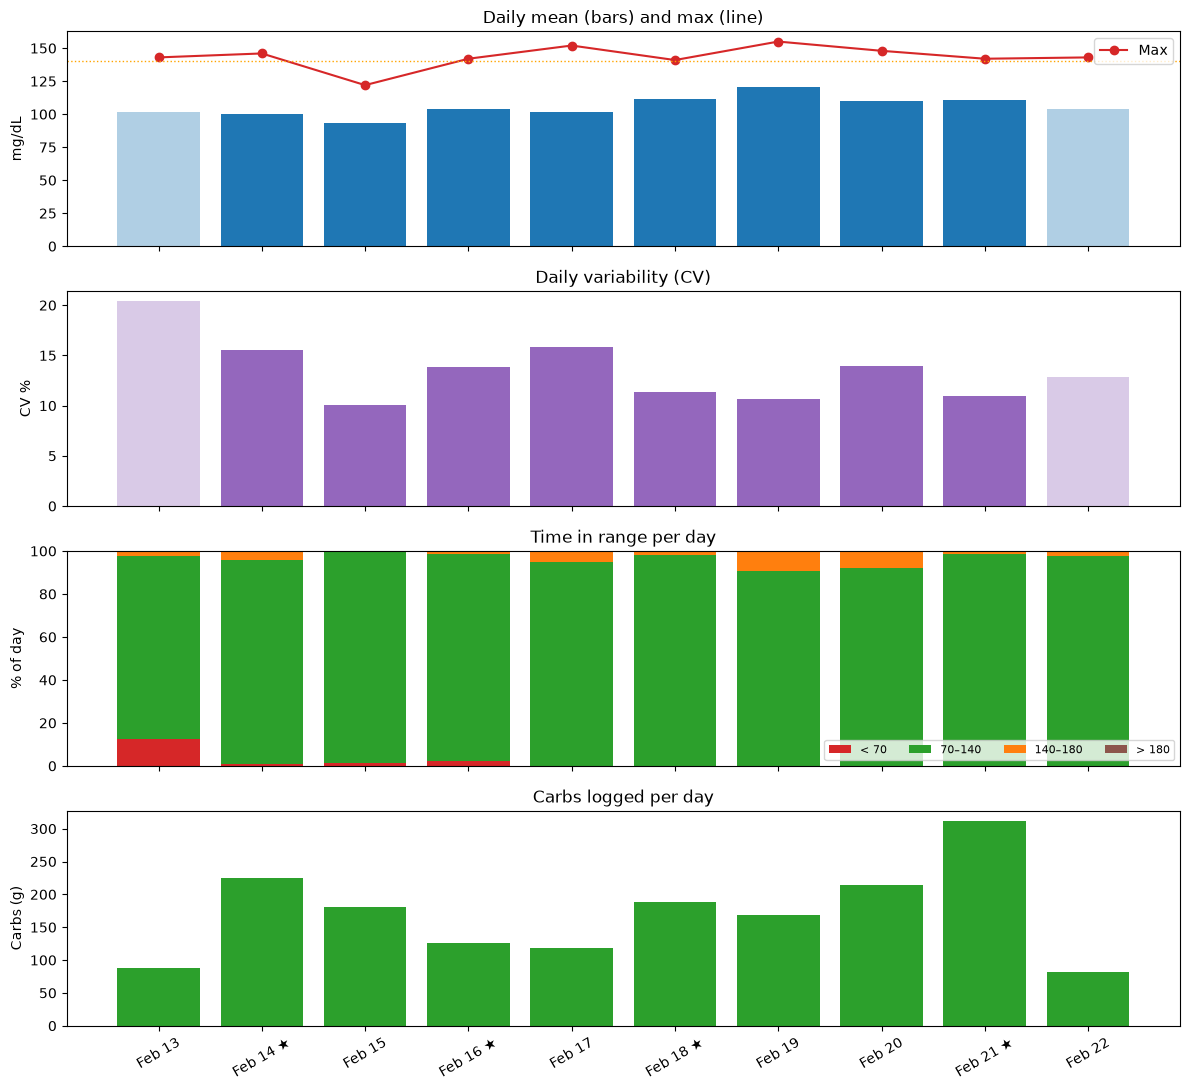

In [9]:
labels = [f"{d:%b %d}{' ★' if s else ''}" for d, s in zip(daily.index, daily["standard"])]
x = np.arange(len(daily))
alpha = np.where(daily["full_day"], 1.0, 0.35)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)

# 1. Mean and max
for i in x:
    axes[0].bar(i, daily["mean"].iloc[i], color="tab:blue", alpha=alpha[i])
axes[0].plot(x, daily["max"], "o-", color="tab:red", label="Max")
axes[0].axhline(HIGH, color="orange", ls=":", lw=1)
axes[0].set_ylabel("mg/dL")
axes[0].set_title("Daily mean (bars) and max (line)")
axes[0].legend()

# 2. CV
for i in x:
    axes[1].bar(i, daily["CV %"].iloc[i], color="tab:purple", alpha=alpha[i])
axes[1].set_ylabel("CV %")
axes[1].set_title("Daily variability (CV)")

# 3. Time in range (stacked)
cols = ["% < 70", "% 70–140", "% 140–180", "% > 180"]
colors = ["#d62728", "#2ca02c", "#ff7f0e", "#8c564b"]
bottom = np.zeros(len(daily))
for c, col in zip(cols, colors):
    axes[2].bar(x, daily[c], bottom=bottom, color=col, label=c.replace("% ", ""))
    bottom += daily[c].values
axes[2].set_ylabel("% of day")
axes[2].set_title("Time in range per day")
axes[2].legend(ncol=4, fontsize=8, loc="lower right")

# 4. Carbs logged
axes[3].bar(x, daily["carbs"], color="tab:green")
axes[3].set_ylabel("Carbs (g)")
axes[3].set_title("Carbs logged per day")
axes[3].set_xticks(x)
axes[3].set_xticklabels(labels, rotation=30)

plt.tight_layout()
plt.show()

---
## Q2: Most stable and most variable day

No single number captures "stability", so we rank full days on three measures and average the ranks:
- **CV**: relative spread
- **range**: biggest swing during the day
- **time above 140**: how much of the day was spent high

Rank 1 = most stable.

In [10]:
full["% > 140"] = full["% 140–180"] + full["% > 180"]
ranks = pd.DataFrame({
    "CV rank": full["CV %"].rank(),
    "range rank": full["range"].rank(),
    "high rank": full["% > 140"].rank(),
})
ranks["average rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.join(full[["CV %", "range", "% > 140", "max", "standard"]].round(1)).sort_values("average rank")
ranks

,CV rank,range rank,high rank,average rank,CV %,range,% > 140,max,standard
date,,,,,,,,,
2020-02-15,1.0,3.0,1.0,1.67,10.1,60.0,0.0,122.0,False
2020-02-21,3.0,1.0,2.5,2.17,10.9,55.0,1.4,142.0,True
2020-02-18,4.0,4.0,4.0,4.00,11.3,67.0,2.1,141.0,True
2020-02-19,2.0,2.0,8.0,4.00,10.6,56.0,9.2,155.0,False
2020-02-16,5.0,8.0,2.5,5.17,13.8,96.0,1.4,142.0,True
2020-02-20,6.0,5.0,7.0,6.00,13.9,72.0,7.8,148.0,False
2020-02-14,7.0,7.0,5.0,6.33,15.5,80.0,4.2,146.0,True
2020-02-17,8.0,6.0,6.0,6.67,15.9,74.0,5.2,152.0,False


In [11]:
most_stable = ranks.index[0]
most_variable = ranks.index[-1]
print("Most stable day:  ", most_stable)
print("Most variable day:", most_variable)

Most stable day:   2020-02-15
Most variable day: 2020-02-17


### Most stable vs most variable day

Both days plotted by clock time, with their meals marked. Comparing the meal markers often explains the difference.

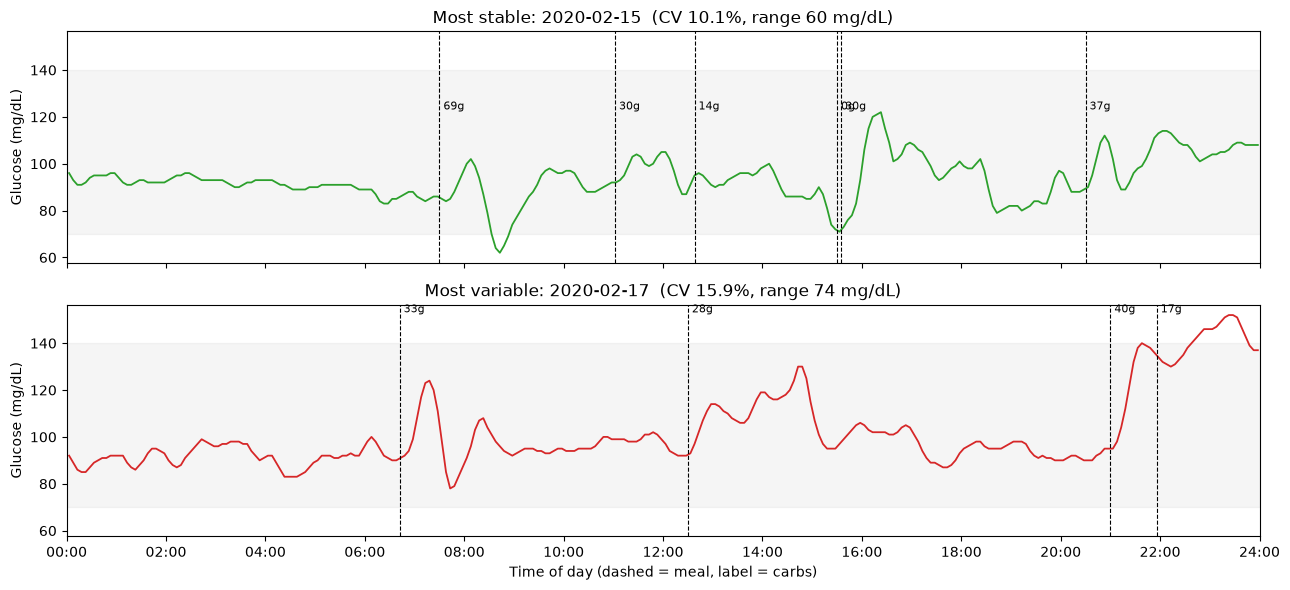

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)

for ax, d, col, name in [(axes[0], most_stable, "tab:green", "Most stable"),
                          (axes[1], most_variable, "tab:red", "Most variable")]:
    day_df = glu[glu["date"] == d]
    ax.plot(day_df["tod"], day_df["glucose"], color=col, lw=1.3)
    ax.axhspan(70, 140, color="gray", alpha=0.08)
    for _, m in meals[meals["date"] == d].iterrows():
        ax.axvline(m["tod"], color="black", ls="--", lw=0.8)
        ax.text(m["tod"], day_df["glucose"].max(), f" {m['carbs']:.0f}g", fontsize=8, va="bottom")
    ax.set_title(f"{name}: {d}  (CV {full.loc[d, 'CV %']:.1f}%, range {full.loc[d, 'range']:.0f} mg/dL)")
    ax.set_ylabel("Glucose (mg/dL)")

axes[1].set_xlim(0, 24)
axes[1].set_xticks(range(0, 25, 2))
axes[1].set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 2)])
axes[1].set_xlabel("Time of day (dashed = meal, label = carbs)")
plt.tight_layout()
plt.show()

In [12]:
print("Meals on the most stable day:")
print(meals.loc[meals["date"] == most_stable, ["time", "foods", "carbs", "sugar"]].to_string(index=False))
print("\nMeals on the most variable day:")
print(meals.loc[meals["date"] == most_variable, ["time", "foods", "carbs", "sugar"]].to_string(index=False))

Meals on the most stable day:
               time                                              foods  carbs  sugar
2020-02-15 07:30:00                                   Spinach Smoothie   69.0   38.0
2020-02-15 11:02:00                                Breakfast Trail Mix   30.0   22.0
2020-02-15 12:38:00 Spinach Salad w/ blueberries, egg, and cheese, Egg   14.4    8.7
2020-02-15 15:30:00                                       Babel Cheese    0.3    0.3
2020-02-15 15:35:00                                Breakfast Trail Mix   30.0   22.0
2020-02-15 20:30:00             Bourbon Chicken, Rice, Shrimp, Cabbage   37.2   11.5

Meals on the most variable day:
               time                                   foods  carbs  sugar
2020-02-17 06:42:00               Maple Brown Sugar Oatmeal   33.0   13.0
2020-02-17 12:30:00 Chicken Nuggets, Salad with Cranberries   28.2   17.0
2020-02-17 21:00:00                       Kale Salad, Pizza   40.0    5.9
2020-02-17 21:56:00                           

---
## Q3: Is there a trend across the study?

We fit a straight line through the daily values against day number. The **slope** tells you how much the value changes per day on average.

Things to keep in mind:
- With only ~8 full days, a trend has to be quite strong to be statistically convincing, so treat the p-value as a rough guide.
- A trend can be **behavioural** (e.g. eating differently as the study goes on) or **technical**: CGM sensors can drift slightly over their 10-day life, and Stage 1 found the first 24 h read lower than the rest.

We test the trend with and without the first full day to see how much that day drives the result.

In [13]:
def trend(df, col):
    res = stats.linregress(df["day_no"], df[col])
    rho, p_rho = stats.spearmanr(df["day_no"], df[col])
    return pd.Series({"slope per day": res.slope, "r": res.rvalue, "p (linear)": res.pvalue,
                      "Spearman rho": rho, "p (Spearman)": p_rho})

metrics = ["mean", "median", "max", "CV %", "% 70–140", "carbs"]
trends = pd.DataFrame({m: trend(full, m) for m in metrics}).T.round(3)
trends

,slope per day,r,p (linear),Spearman rho,p (Spearman)
mean,2.582,0.759,0.029,0.762,0.028
median,2.714,0.755,0.031,0.802,0.017
max,1.548,0.378,0.356,0.275,0.509
CV %,-0.322,-0.344,0.404,-0.190,0.651
% 70–140,-0.260,-0.218,0.603,-0.071,0.867
carbs,11.638,0.464,0.247,0.286,0.493


In [14]:
# Sensitivity check: drop the first full day
trends_wo_first = pd.DataFrame({m: trend(full.iloc[1:], m) for m in metrics}).T.round(3)
compare = pd.DataFrame({
    "slope (all full days)": trends["slope per day"],
    "slope (without first)": trends_wo_first["slope per day"],
    "p (all)": trends["p (linear)"],
    "p (without first)": trends_wo_first["p (linear)"],
})
compare

,slope (all full days),slope (without first),p (all),p (without first)
mean,2.582,2.937,0.029,0.056
median,2.714,2.750,0.031,0.087
max,1.548,2.679,0.356,0.214
CV %,-0.322,-0.088,0.404,0.852
% 70–140,-0.260,-0.453,0.603,0.498
carbs,11.638,22.204,0.247,0.057


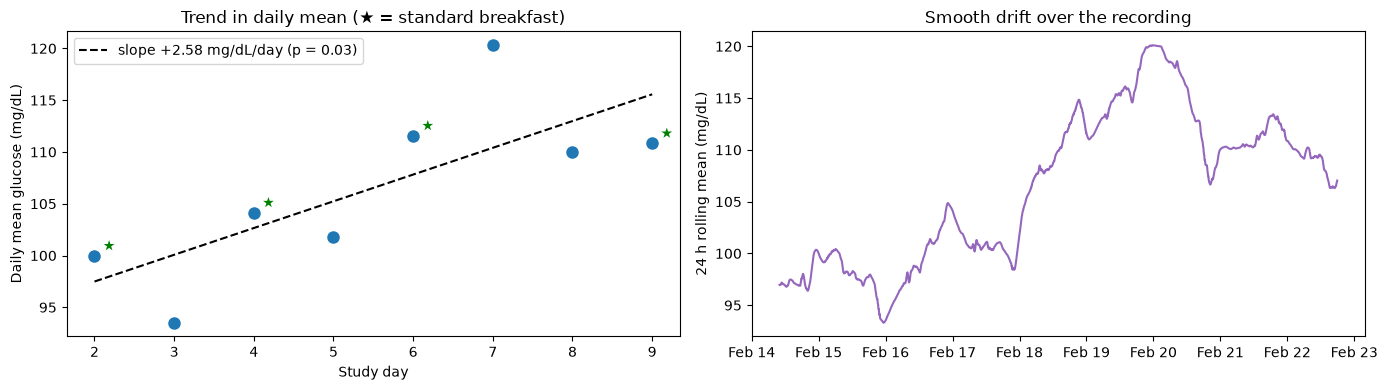

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: daily mean with trend line
res = stats.linregress(full["day_no"], full["mean"])
axes[0].plot(full["day_no"], full["mean"], "o", ms=8, color="tab:blue")
axes[0].plot(full["day_no"], res.intercept + res.slope * full["day_no"], "--", color="black",
             label=f"slope {res.slope:+.2f} mg/dL/day (p = {res.pvalue:.2f})")
for _, r in full[full["standard"]].iterrows():
    axes[0].annotate("★", (r["day_no"], r["mean"]), textcoords="offset points", xytext=(6, 4), color="green")
axes[0].set_xlabel("Study day")
axes[0].set_ylabel("Daily mean glucose (mg/dL)")
axes[0].set_title("Trend in daily mean (★ = standard breakfast)")
axes[0].legend()

# Right: rolling 24 h mean over the whole recording
roll = glu.set_index("timestamp")["glucose"].rolling("24h", min_periods=200).mean()
axes[1].plot(roll.index, roll.values, color="tab:purple")
axes[1].set_ylabel("24 h rolling mean (mg/dL)")
axes[1].set_title("Smooth drift over the recording")
axes[1].xaxis.set_major_locator(mdates.DayLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.tight_layout()
plt.show()

---
## Q4: Standard breakfast days vs other days

On standard breakfast days, the participant ate the same breakfast (Frosted Flakes with milk), so their mornings are controlled. We compare those days with the other full days, both for the **whole day** and for the **morning** (06:00–12:00), where the breakfast effect should be strongest.

With about 4 days per group, this comparison is descriptive. The Mann–Whitney p-values are included for completeness but can't be very convincing at this sample size.

In [15]:
compare_cols = ["mean", "max", "SD", "CV %", "% 70–140", "% > 140", "excursions > 140", "carbs"]

groups = full.groupby("standard")[compare_cols].mean().T
groups.columns = ["Other days" if not c else "Standard breakfast days" for c in groups.columns]
groups["difference"] = groups.get("Standard breakfast days", np.nan) - groups.get("Other days", np.nan)

pvals = {}
for c in compare_cols:
    a = full.loc[full["standard"], c]
    b = full.loc[~full["standard"], c]
    pvals[c] = stats.mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan
groups["p (Mann–Whitney)"] = pd.Series(pvals)

print("Days per group:", full["standard"].value_counts().rename({True: "standard", False: "other"}).to_dict())
groups.round(2)

Days per group: {'standard': 4, 'other': 4}


,Other days,Standard breakfast days,difference,p (Mann–Whitney)
mean,106.42,106.63,0.21,0.89
max,144.25,142.75,-1.50,0.31
SD,13.43,13.67,0.24,0.89
CV %,12.63,12.90,0.27,0.89
% 70–140,94.10,97.05,2.95,0.20
% > 140,5.55,2.26,-3.29,0.31
excursions > 140,2.50,2.25,-0.25,0.76
carbs,170.75,212.60,41.85,0.34


In [16]:
# Morning window only (06:00–12:00)
morning = glu[(glu["tod"] >= 6) & (glu["tod"] < 12) & glu["date"].isin(full.index)].copy()
morning["standard"] = morning["date"].isin(standard_days)

morning_daily = morning.groupby(["date", "standard"])["glucose"].agg(
    mean="mean", max="max", SD="std",
    pct_above_140=lambda s: (s >= HIGH).mean() * 100,
).reset_index()

morning_daily.groupby("standard")[["mean", "max", "SD", "pct_above_140"]].mean() \
    .rename(index={True: "Standard breakfast", False: "Other"}).round(1)

,mean,max,SD,pct_above_140
standard,,,,
Other,99.6,121.8,8.6,1.0
Standard breakfast,99.3,134.5,14.2,1.4


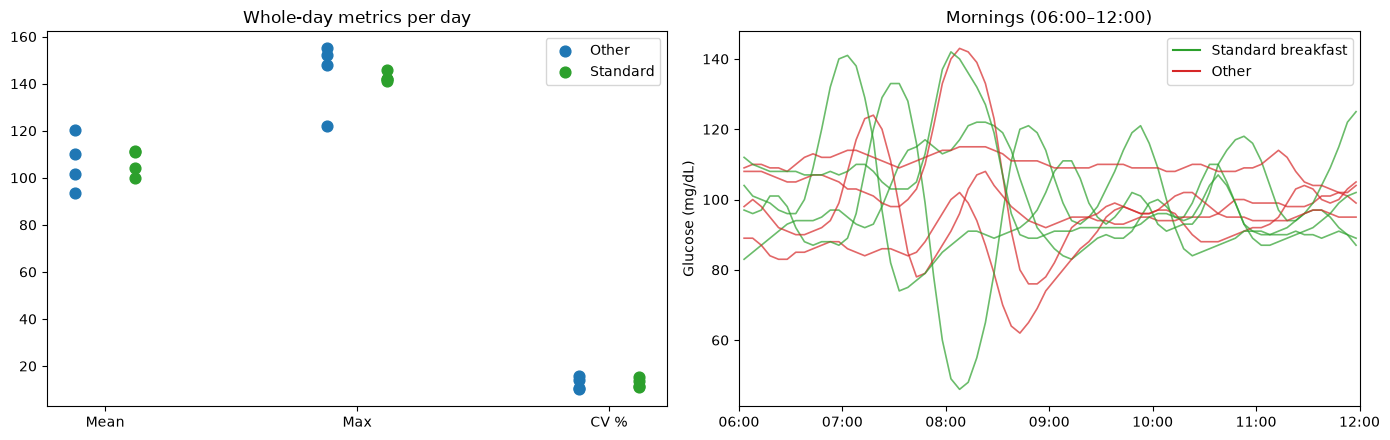

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: whole-day metrics as strip plot
for i, c in enumerate(["mean", "max", "CV %"]):
    for s, col, off in [(False, "tab:blue", -0.12), (True, "tab:green", 0.12)]:
        vals = full.loc[full["standard"] == s, c]
        axes[0].scatter(np.full(len(vals), i + off), vals, color=col, s=60,
                        label=("Standard" if s else "Other") if i == 0 else None)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(["Mean", "Max", "CV %"])
axes[0].set_title("Whole-day metrics per day")
axes[0].legend()

# Right: morning traces by group
for d in full.index:
    m = morning[morning["date"] == d]
    s = d in standard_days
    axes[1].plot(m["tod"], m["glucose"], color="tab:green" if s else "tab:red", alpha=0.7, lw=1.2)
axes[1].plot([], [], color="tab:green", label="Standard breakfast")
axes[1].plot([], [], color="tab:red", label="Other")
axes[1].set_xlim(6, 12)
axes[1].set_xticks(range(6, 13))
axes[1].set_xticklabels([f"{h:02d}:00" for h in range(6, 13)])
axes[1].set_ylabel("Glucose (mg/dL)")
axes[1].set_title("Mornings (06:00–12:00)")
axes[1].legend()
plt.tight_layout()
plt.show()

---
## Q5 (added): How similar is each day to the next? (MODD)

**MODD** (Mean Of Daily Differences) is a standard CGM measure of day-to-day consistency. It compares glucose at the **same clock time** on two consecutive days, takes the absolute difference, and averages it.

- Low MODD → days follow a similar pattern (regular routine)
- High MODD → days differ a lot (irregular meals, activity, or sleep)

We also correlate the hourly profiles of every pair of days. Days with a high correlation have a similar *shape*, even if their levels differ.

In [19]:
# Regular 5-min grid (same approach as Stage 3) so "same time yesterday" is exactly 288 slots back
start = glu["timestamp"].iloc[0]
slot = ((glu["timestamp"] - start) / INTERVAL).round().astype(int)
grid = glu.assign(slot=slot).drop_duplicates("slot").set_index("slot")["glucose"].reindex(range(slot.max() + 1))
grid.index = start + grid.index * INTERVAL

diff_24h = (grid - grid.shift(288)).abs()
modd = diff_24h.mean()
print(f"MODD: {modd:.1f} mg/dL  (based on {diff_24h.count()} paired readings)")

MODD: 15.3 mg/dL  (based on 2235 paired readings)


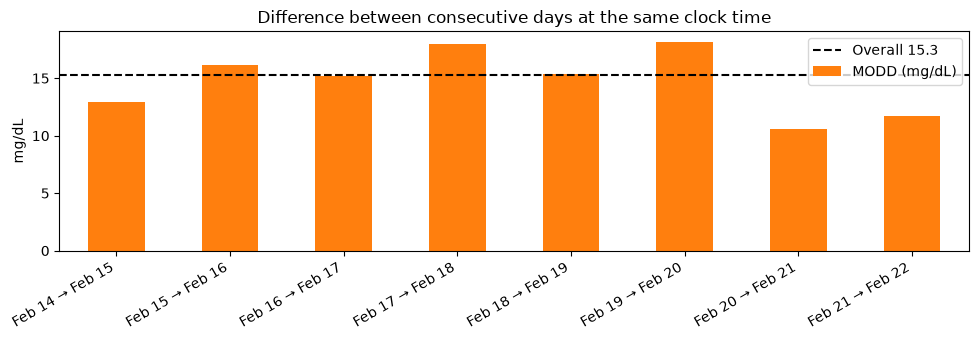

,MODD (mg/dL),paired readings
Feb 14 → Feb 15,12.9,287
Feb 15 → Feb 16,16.2,287
Feb 16 → Feb 17,15.2,288
Feb 17 → Feb 18,18.0,288
Feb 18 → Feb 19,15.4,284
Feb 19 → Feb 20,18.2,251
Feb 20 → Feb 21,10.6,255
Feb 21 → Feb 22,11.7,215


In [20]:
# MODD for each consecutive pair of days
pair_modd = diff_24h.groupby(diff_24h.index.date).agg(["mean", "count"])
pair_modd = pair_modd[pair_modd["count"] >= 144]
pair_modd.index = [f"{pd.Timestamp(d) - pd.Timedelta('1D'):%b %d} → {d:%b %d}" for d in pair_modd.index]
pair_modd.columns = ["MODD (mg/dL)", "paired readings"]

ax = pair_modd["MODD (mg/dL)"].plot(kind="bar", figsize=(10, 3.5), color="tab:orange")
ax.axhline(modd, color="black", ls="--", label=f"Overall {modd:.1f}")
ax.set_ylabel("mg/dL")
ax.set_title("Difference between consecutive days at the same clock time")
ax.legend()
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
pair_modd.round(1)

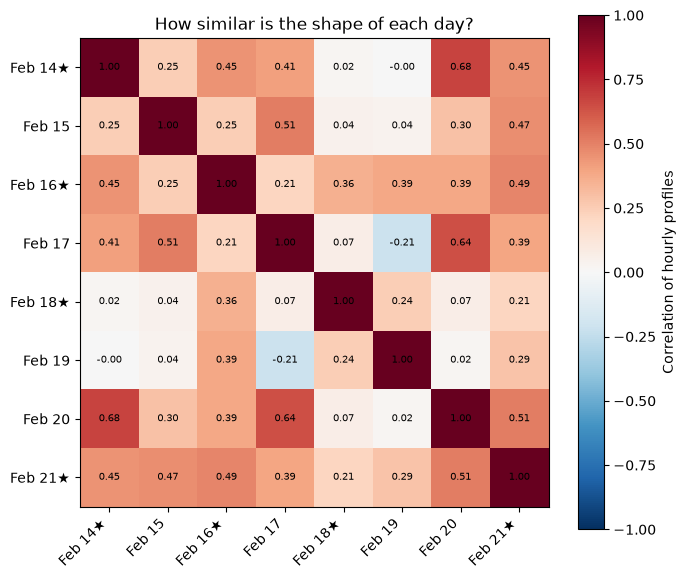

Average day-to-day profile correlation: 0.28


In [21]:
profiles = glu[glu["date"].isin(full.index)].assign(hour=lambda d: d["timestamp"].dt.hour) \
    .pivot_table(index="hour", columns="date", values="glucose", aggfunc="mean")
corr = profiles.corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
names = [f"{d:%b %d}{'★' if d in standard_days else ''}" for d in corr.index]
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(names)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="Correlation of hourly profiles")
ax.set_title("How similar is the shape of each day?")
plt.tight_layout()
plt.show()

off_diag = corr.where(~np.eye(len(corr), dtype=bool)).stack()
print(f"Average day-to-day profile correlation: {off_diag.mean():.2f}")

---
## Q6 (added): Does daily intake relate to daily glucose?

We compare logged carbs, sugar, and calories per day with the day's mean, max, and time above 140.

Food logs are often incomplete. A day with only one or two logged meals probably has missing entries, so those days are marked and also excluded in a second version of the test. Spearman correlation is used because it is less sensitive to a single unusual day.

In [22]:
full["well_logged"] = full["meals"] >= 3

def intake_corr(df):
    out = {}
    for x in ["carbs", "sugar", "calories"]:
        for y in ["mean", "max", "% > 140"]:
            rho, p = stats.spearmanr(df[x], df[y])
            out[(x, y)] = {"rho": rho, "p": p}
    return pd.DataFrame(out).T.round(2)

print("Days with ≥ 3 meals logged:", int(full["well_logged"].sum()), "of", len(full))
intake_all = intake_corr(full)
intake_well = intake_corr(full[full["well_logged"]]) if full["well_logged"].sum() >= 4 else None
intake_all.join(intake_well, rsuffix=" (well-logged)") if intake_well is not None else intake_all

Days with ≥ 3 meals logged: 8 of 8


rho     p  rho (well-logged)  p (well-logged)
carbs    mean     0.10  0.82               0.10             0.82
         max     -0.26  0.53              -0.26             0.53
         % > 140 -0.14  0.73              -0.14             0.73
sugar    mean    -0.31  0.46              -0.31             0.46
         max      0.00  1.00               0.00             1.00
         % > 140  0.14  0.73               0.14             0.73
calories mean     0.21  0.61               0.21             0.61
         max     -0.56  0.15              -0.56             0.15
         % > 140 -0.47  0.24              -0.47             0.24

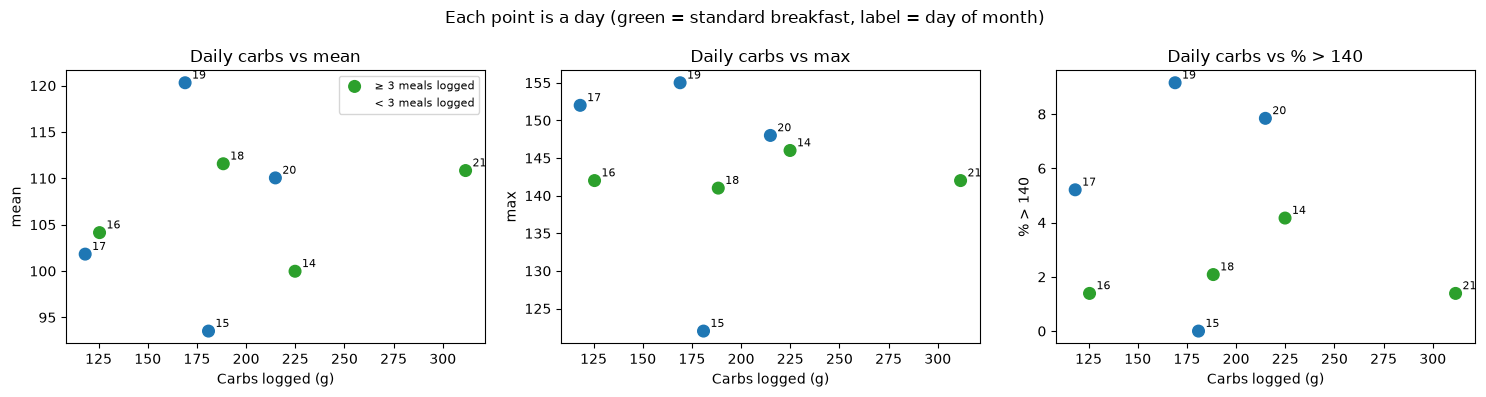

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, y in zip(axes, ["mean", "max", "% > 140"]):
    for well, mk in [(True, "o"), (False, "x")]:
        sub = full[full["well_logged"] == well]
        ax.scatter(sub["carbs"], sub[y], marker=mk, s=70,
                   c=np.where(sub["standard"], "tab:green", "tab:blue"),
                   label="≥ 3 meals logged" if well else "< 3 meals logged")
    for d, r in full.iterrows():
        ax.annotate(f"{d:%d}", (r["carbs"], r[y]), textcoords="offset points", xytext=(5, 3), fontsize=8)
    ax.set_xlabel("Carbs logged (g)")
    ax.set_ylabel(y)
    ax.set_title(f"Daily carbs vs {y}")
    
axes[0].legend(fontsize=8)
plt.suptitle("Each point is a day (green = standard breakfast, label = day of month)")
plt.tight_layout()
plt.show()

---
## Summary

All Stage 5 answers in one table. The full per-day table is saved too, so it can be combined with other participants later.

In [24]:
mean_trend = trends.loc["mean"]
std_mean = full.loc[full["standard"], "mean"].mean()
oth_mean = full.loc[~full["standard"], "mean"].mean()

summary = pd.Series({
    "Full days analysed": len(full),
    "Daily mean range (mg/dL)": f"{full['mean'].min():.0f}–{full['mean'].max():.0f}",
    "Daily max range (mg/dL)": f"{full['max'].min():.0f}–{full['max'].max():.0f}",
    "Daily CV range (%)": f"{full['CV %'].min():.1f}–{full['CV %'].max():.1f}",
    "Most stable day": str(most_stable),
    "Most variable day": str(most_variable),
    "Trend in daily mean (mg/dL/day)": round(mean_trend["slope per day"], 2),
    "Trend p-value": round(mean_trend["p (linear)"], 3),
    "Trend without first day (mg/dL/day)": round(trends_wo_first.loc["mean", "slope per day"], 2),
    "Mean glucose, standard breakfast days": round(std_mean, 1),
    "Mean glucose, other days": round(oth_mean, 1),
    "MODD (mg/dL)": round(modd, 1),
    "Avg day-to-day profile correlation": round(off_diag.mean(), 2),
    "Carbs vs daily mean (Spearman rho)": intake_all.loc[("carbs", "mean"), "rho"],
}, name=PID)

summary.to_frame()

,001
Full days analysed,8
Daily mean range (mg/dL),94–120
Daily max range (mg/dL),122–155
Daily CV range (%),10.1–15.9
Most stable day,2020-02-15
Most variable day,2020-02-17
Trend in daily mean (mg/dL/day),2.58
Trend p-value,0.029
Trend without first day (mg/dL/day),2.94
"Mean glucose, standard breakfast days",106.6


In [26]:
summary.to_frame().T.rename_axis("participant").to_csv(f"../clean_data/stage5_summary_{PID}.csv")
daily.round(2).to_csv(f"../clean_data/stage5_daily_{PID}.csv")
print(f"Saved stage5_summary_{PID}.csv and stage5_daily_{PID}.csv")

Saved stage5_summary_001.csv and stage5_daily_001.csv
